# Finite-state transition matrices

Compile a parity recogniser into one transition matrix for each input symbol.

Represent even and odd parity by one-hot row vectors. Reading zero preserves the state and reading one exchanges the two coordinates. The recurrent update multiplies by the matrix selected by the current symbol.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import product

## Construct the weights and test their behaviour

Inspect the arrays and the reference output. Each check describes a specific property of the constructed model.

words tested 511 state path [0 1 0 0 1 1 1 0 0]


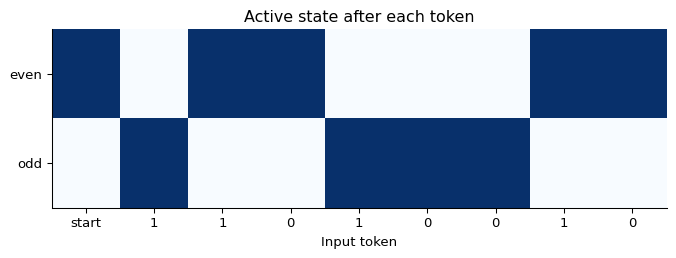

In [2]:
T = np.array([np.eye(2), [[0, 1], [1, 0]]])
start = np.array([1, 0])


def states(word):
    result = [start]
    for bit in word:
        result.append(result[-1] @ T[bit])
    return np.stack(result)


words = [w for n in range(9) for w in product([0, 1], repeat=n)]
assert all(states(w)[-1].argmax() == sum(w) % 2 for w in words)
word = [1, 1, 0, 1, 0, 0, 1, 0]
trace = states(word)
print("words tested", len(words), "state path", trace.argmax(1))
fig, ax = plt.subplots(figsize=(7, 2.6), constrained_layout=True)
ax.imshow(trace.T, aspect="auto", cmap="Blues")
ax.set(
    xticks=range(len(trace)),
    xticklabels=["start", *map(str, word)],
    yticks=[0, 1],
    yticklabels=["even", "odd"],
    xlabel="Input token",
    title="Active state after each token",
)
plt.show()

## Interpreting the result

The induction step is visible in the two matrices. One preserves parity, the other toggles it, which extends the finite test to words of any length.

## Exercise

Compile a three-state machine that counts ones modulo three.

## References

[Stanford CS103, finite automata and regular languages](https://web.stanford.edu/class/cs103/)

[WeightCode, weight-space programming preprint (2026)](https://arxiv.org/abs/2611.25476)